# **Assignment 09**

---

## **Import External Libraries**

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

from IPython.display import display, Math

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit.library import SwapGate
from qiskit.quantum_info import Operator, Statevector
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeMarrakesh

In [2]:
# --- Shared helpers: qubit order |q_{n-1} ... q_1 q_0>, MSB = first tensor factor (IBM-Q convention) ---
def latex_matrix(M):
    """LaTeX for a numeric array: rounded to 4 d.p., whole numbers shown as integers."""
    M = np.round(np.real_if_close(np.asarray(M, dtype=complex)), 4) + 0.0
    return sp.latex(sp.Matrix(M).applyfunc(lambda v: sp.Integer(int(v)) if float(v).is_integer() else v))


def ket(bits):
    """Basis column vector |bits>, e.g. ket("01") = (0, 1, 0, 0)."""
    v = np.zeros(2 ** len(bits))
    v[int(bits, 2)] = 1
    return v


def kron(*ms):
    out = np.array([[1.0]])
    for m in ms:
        out = np.kron(out, m)
    return out


I2 = np.eye(2)
X  = np.array([[0, 1], [1, 0]])
Z  = np.array([[1, 0], [0, -1]])
H  = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
P0 = np.array([[1, 0], [0, 0]])   # |0><0|
P1 = np.array([[0, 0], [0, 1]])   # |1><1|

CNOT = kron(P0, I2) + kron(P1, X)   # control = MSB q1, target = LSB q0
CZ   = kron(P0, I2) + kron(P1, Z)
HH   = kron(H, H)

# Simulators: ideal, and with the noise model of IBM's ibm_marrakesh (a snapshot of its calibration)
SHOTS   = 1024
SEED    = 2110515
ideal   = AerSimulator(seed_simulator=SEED)
backend = FakeMarrakesh()
noisy   = AerSimulator.from_backend(backend, seed_simulator=SEED)


def run(qc, sim):
    tqc = transpile(qc, sim, optimization_level=1, seed_transpiler=SEED)
    return sim.run(tqc, shots=SHOTS).result().get_counts()


def report(cnt, label, nbits):
    print(label)
    for k in range(2 ** nbits):
        key = format(k, f"0{nbits}b")
        print(f"  {key}:  {cnt.get(key, 0):4d} / {SHOTS}")


def histograms(panels, filename, nbits, ncols=None):
    """One horizontal histogram per panel; each panel = (title, ideal counts, noisy counts)."""
    ncols = ncols or len(panels)
    nrows = -(-len(panels) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.6 * nrows), squeeze=False)
    keys = [format(k, f"0{nbits}b") for k in range(2 ** nbits)][::-1]
    y = np.arange(len(keys))
    for ax, (title, ci, cn) in zip(axes.flat, panels):
        ax.barh(y + 0.2, [ci.get(k, 0) for k in keys], height=0.4, color="#6fa8dc", label="ideal")
        ax.barh(y - 0.2, [cn.get(k, 0) for k in keys], height=0.4, color="#e69138", label="noisy (ibm_marrakesh)")
        ax.set_yticks(y, keys)
        ax.set_xlim(0, SHOTS)
        ax.set_xlabel("Frequency")
        ax.set_ylabel("Measurement outcome")
        ax.set_title(title)
        ax.grid(axis="x", alpha=0.4)
    for ax in list(axes.flat)[len(panels):]:
        ax.axis("off")
    axes.flat[0].legend(loc="lower right", fontsize=7)
    fig.tight_layout()
    fig.savefig(f"../images/{filename}", dpi=200, bbox_inches="tight")
    display(fig)
    plt.close(fig)

---

## **1. The General Form of XOR Quantum Oracle**

In [3]:
# --- Problem 1: x = 5, f(5) = 3, n = 3, m = 3 ---
n, m, x, fx, y = 3, 3, 5, 3, 0
x_bits, y_bits  = format(x, f"0{n}b"), format(y, f"0{m}b")
out_bits        = format(y ^ fx, f"0{m}b")
print(f"Problem 1  --  input  |x>_3|y>_3 = |{x_bits}>|{y_bits}> = |{x_bits + y_bits}>  (decimal {int(x_bits + y_bits, 2)})")
print(f"Problem 1  --  output |x>_3|y XOR f(x)>_3 = |{x_bits}>|{out_bits}> = |{x_bits + out_bits}>  (decimal {int(x_bits + out_bits, 2)})")

Problem 1  --  input  |x>_3|y>_3 = |101>|000> = |101000>  (decimal 40)
Problem 1  --  output |x>_3|y XOR f(x)>_3 = |101>|011> = |101011>  (decimal 43)


---

## **2. Unitarity of XOR Quantum Oracle**

In [4]:
# --- Problem 2: U_f is unitary for ANY f: {0,1}^n -> {0,1}^m, even a non-injective one ---
def xor_oracle(f, n, m):
    """Matrix of U_f |x>_n |y>_m = |x>_n |y XOR f(x)>_m  (x = the n MSB, y = the m LSB)."""
    N = 2 ** (n + m)
    U = np.zeros((N, N))
    for xx in range(2 ** n):
        for yy in range(2 ** m):
            U[(xx << m) | (yy ^ f(xx)), (xx << m) | yy] = 1   # column |x>|y>  ->  row |x>|y XOR f(x)>
    return U


rng = np.random.default_rng(SEED)
for trial in range(5):
    table = [int(v) for v in rng.integers(0, 2 ** 3, size=2 ** 3)]   # a random f: {0,1}^3 -> {0,1}^3
    U = xor_oracle(lambda xx: table[xx], 3, 3)
    print(f"Problem 2  --  f = {table}:  U^dagger U == I ? {np.allclose(U.T @ U, np.eye(64))},"
          f"  U U == I ? {np.allclose(U @ U, np.eye(64))}")

Problem 2  --  f = [2, 4, 4, 0, 2, 3, 4, 6]:  U^dagger U == I ? True,  U U == I ? True
Problem 2  --  f = [3, 7, 6, 1, 2, 1, 7, 0]:  U^dagger U == I ? True,  U U == I ? True
Problem 2  --  f = [0, 5, 6, 4, 3, 6, 3, 1]:  U^dagger U == I ? True,  U U == I ? True
Problem 2  --  f = [2, 7, 2, 0, 0, 5, 1, 4]:  U^dagger U == I ? True,  U U == I ? True
Problem 2  --  f = [5, 6, 1, 7, 2, 4, 6, 3]:  U^dagger U == I ? True,  U U == I ? True


---

## **3. Construction of SWAP-gate**

In [5]:
# --- Problem 3: SWAP = sum_{i,j} <j|SWAP|i> |j><i| ---
basis = ["00", "01", "10", "11"]
swap_action = {"00": "00", "01": "10", "10": "01", "11": "11"}   # SWAP|q1 q0> = |q0 q1>

SWAP = np.zeros((4, 4))
for i in basis:
    for j in basis:
        coeff = ket(j) @ ket(swap_action[i])                   # <j| SWAP |i>
        if coeff:
            print(f"Problem 3  --  <{j}|SWAP|{i}> = {coeff:.0f}")
        SWAP += coeff * np.outer(ket(j), ket(i))

display(Math(r"\text{SWAP} = " + latex_matrix(SWAP)))
print("Problem 3  --  equals Qiskit's SwapGate ?", np.allclose(SWAP, Operator(SwapGate()).data))

Problem 3  --  <00|SWAP|00> = 1
Problem 3  --  <10|SWAP|01> = 1
Problem 3  --  <01|SWAP|10> = 1
Problem 3  --  <11|SWAP|11> = 1


<IPython.core.display.Math object>

Problem 3  --  equals Qiskit's SwapGate ? True


---

## **4. Deutsch Algorithm**

In [6]:
# --- Problem 4: XOR oracles of f_A ... f_D (x = MSB q1, y = LSB q0) and their gate circuits ---
functions = {"A": (0, 0), "B": (0, 1), "C": (1, 0), "D": (1, 1)}   # (f(0), f(1))


def oracle_circuit(name):
    qc = QuantumCircuit(2, name=f"U_f{name}")
    if name == "B":
        qc.cx(1, 0)                 # y XOR x
    elif name == "C":
        qc.cx(1, 0)                 # y XOR x ...
        qc.x(0)                     # ... XOR 1  =  y XOR f_C(x), since f_C(x) = 1 XOR x
    elif name == "D":
        qc.x(0)                     # y XOR 1
    return qc                       # f_A: identity


for name, (f0, f1) in functions.items():
    U = xor_oracle(lambda xx: (f0, f1)[xx], 1, 1)
    display(Math(rf"U_{{f_{name}}} = " + latex_matrix(U)))
    print(f"Problem 4  --  f_{name}: gate circuit matches the matrix ?",
          np.allclose(Operator(oracle_circuit(name)).data, U))

<IPython.core.display.Math object>

Problem 4  --  f_A: gate circuit matches the matrix ? True


<IPython.core.display.Math object>

Problem 4  --  f_B: gate circuit matches the matrix ? True


<IPython.core.display.Math object>

Problem 4  --  f_C: gate circuit matches the matrix ? True


<IPython.core.display.Math object>

Problem 4  --  f_D: gate circuit matches the matrix ? True


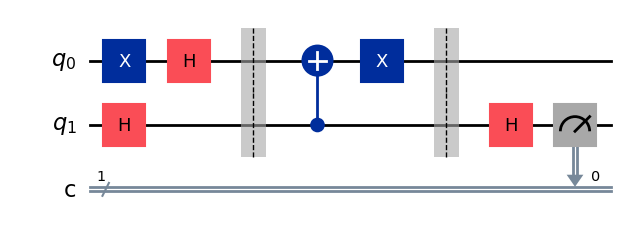

f_A (constant), ideal
  0:  1024 / 1024
  1:     0 / 1024
f_A (constant), noisy
  0:  1020 / 1024
  1:     4 / 1024


f_B (balanced), ideal
  0:     0 / 1024
  1:  1024 / 1024
f_B (balanced), noisy
  0:    10 / 1024
  1:  1014 / 1024


f_C (balanced), ideal
  0:     0 / 1024
  1:  1024 / 1024
f_C (balanced), noisy
  0:    10 / 1024
  1:  1014 / 1024


f_D (constant), ideal
  0:  1024 / 1024
  1:     0 / 1024
f_D (constant), noisy
  0:  1020 / 1024
  1:     4 / 1024


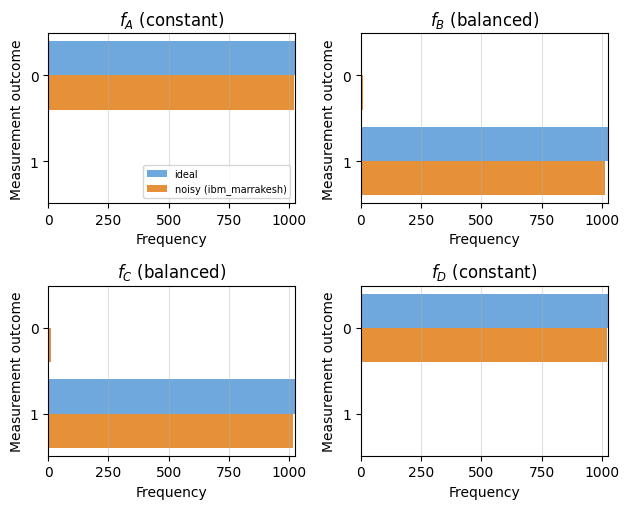

In [7]:
# --- Problem 4: the Deutsch circuit with each oracle, ideal and with ibm_marrakesh noise ---
def deutsch(name):
    qc = QuantumCircuit(QuantumRegister(2, "q"), ClassicalRegister(1, "c"))
    qc.x(0)                          # auxiliary qubit |1> ...
    qc.h([0, 1])                     # ... -> |->, and x -> |+>
    qc.barrier()
    qc.compose(oracle_circuit(name), inplace=True)
    qc.barrier()
    qc.h(1)
    qc.measure(1, 0)                 # 0 = constant, 1 = balanced
    return qc


display(deutsch("C").draw("mpl"))
plt.close("all")

panels = []
for name, (f0, f1) in functions.items():
    ci, cn = run(deutsch(name), ideal), run(deutsch(name), noisy)
    kind = "constant" if f0 == f1 else "balanced"
    report(ci, f"f_{name} ({kind}), ideal", 1)
    report(cn, f"f_{name} ({kind}), noisy", 1)
    panels.append((rf"$f_{name}$ ({kind})", ci, cn))
histograms(panels, "problem-4-answer.png", 1, ncols=2)

---

## **5. Rotation of |Φ⟩**

In [8]:
# --- Problem 5: signed angles of the rotated |Phi> (from |a_perp> towards |a>), N = 4, a = 1 ---
n, a = 2, 1
N = 2 ** n
phi    = np.ones(N) / np.sqrt(N)
a_vec  = ket(format(a, f"0{n}b"))
a_perp = (np.ones(N) - a_vec) / np.sqrt(N - 1)
V = np.eye(N) - 2 * np.outer(a_vec, a_vec)
W = 2 * np.outer(phi, phi) - np.eye(N)
theta = np.degrees(np.arcsin(1 / np.sqrt(N)))


def angle_from_a_perp(v):
    return np.degrees(np.arctan2(a_vec @ v, a_perp @ v))


# (WV)^k |Phi> sits at (2k+1) theta, V (WV)^k |Phi> at -(2k+1) theta; check each against the state vector
print(f"theta = {theta:.1f} deg")
print(f"{'state':>14} {'to |a_perp>':>12} {'to |a>':>8}   matches the state vector?")
state, label = phi, "|Phi>"
for step in range(9):
    k = step // 2
    formula = (2 * k + 1) * theta * (1 if step % 2 == 0 else -1)
    same = np.isclose((formula - angle_from_a_perp(state) + 180) % 360, 180)
    print(f"{label:>14} {formula:12.1f} {round(90 - formula, 6) + 0.0:8.1f}   {same}")
    op, name = (V, "V") if step % 2 == 0 else (W, "W")
    state, label = op @ state, name + label

theta = 30.0 deg
         state  to |a_perp>   to |a>   matches the state vector?
         |Phi>         30.0     60.0   True
        V|Phi>        -30.0    120.0   True
       WV|Phi>         90.0      0.0   True
      VWV|Phi>        -90.0    180.0   True
     WVWV|Phi>        150.0    -60.0   True
    VWVWV|Phi>       -150.0    240.0   True
   WVWVWV|Phi>        210.0   -120.0   True
  VWVWVWV|Phi>       -210.0    300.0   True
 WVWVWVWV|Phi>        270.0   -180.0   True


---

## **6. Another Form of V**

In [9]:
# --- Problem 6: V = I - 2|a><a|  and  W = 2|Phi><Phi| - I = H (2|0><0| - I) H  (n = 2) ---
n = 2
N = 2 ** n
phi = np.ones(N) / np.sqrt(N)
for a in range(N):
    a_vec = ket(format(a, f"0{n}b"))
    V_def = np.diag([(-1) ** (x == a) for x in range(N)])           # V|x> = (-1)^{f(x)} |x>
    print(f"Problem 6  --  a = {a}:  V == I - 2|a><a| ?", np.allclose(V_def, np.eye(N) - 2 * np.outer(a_vec, a_vec)))

W = 2 * np.outer(phi, phi) - np.eye(N)
print("Problem 6  --  W == H (2|00><00| - I) H ?", np.allclose(W, HH @ (2 * np.outer(ket("00"), ket("00")) - np.eye(N)) @ HH))
print("Problem 6  --  W == -(I - 2|Phi><Phi|) ?", np.allclose(W, -(np.eye(N) - 2 * np.outer(phi, phi))))

Problem 6  --  a = 0:  V == I - 2|a><a| ? True
Problem 6  --  a = 1:  V == I - 2|a><a| ? True
Problem 6  --  a = 2:  V == I - 2|a><a| ? True
Problem 6  --  a = 3:  V == I - 2|a><a| ? True
Problem 6  --  W == H (2|00><00| - I) H ? True
Problem 6  --  W == -(I - 2|Phi><Phi|) ? True


---

## **7. Numerical Substitution I**

In [10]:
# --- Problem 7: n = 2, a = 3 ---
n, a = 2, 3
N = 2 ** n
phi    = np.ones(N) / np.sqrt(N)
a_vec  = ket(format(a, f"0{n}b"))
a_perp = (np.ones(N) - a_vec) / np.sqrt(N - 1)
display(Math(r"\ket{\Phi} = " + sp.latex(sp.Matrix([sp.Rational(1, 2)] * 4).T)))
display(Math(r"\ket{a} = " + latex_matrix(a_vec.reshape(1, -1))))
display(Math(r"\ket{a_\perp} = \tfrac{1}{\sqrt{3}}" + latex_matrix((np.sqrt(3) * a_perp).reshape(1, -1))))
print("Problem 7  --  <a|a_perp> =", round(a_vec @ a_perp, 10), "  cos(theta) = <a_perp|Phi> =", round(a_perp @ phi, 4),
      "  theta =", round(np.degrees(np.arccos(a_perp @ phi)), 2), "deg")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Problem 7  --  <a|a_perp> = 0.0   cos(theta) = <a_perp|Phi> = 0.866   theta = 30.0 deg


---

## **8. Numerical Substitution II**

In [11]:
# --- Problem 8: V|Phi> = c0 |Phi> + c1 |Phi_perp>  (continuing Problem 7, a = 3) ---
theta    = np.arccos(a_perp @ phi)
phi_perp = -np.sin(theta) * a_perp + np.cos(theta) * a_vec
V        = np.eye(N) - 2 * np.outer(a_vec, a_vec)
V_phi    = V @ phi
c0, c1   = phi @ V_phi, phi_perp @ V_phi
display(Math(r"\ket{\Phi_\perp} = \tfrac{1}{2\sqrt{3}}" + latex_matrix((2 * np.sqrt(3) * phi_perp).reshape(1, -1))))
display(Math(r"V\ket{\Phi} = " + latex_matrix(V_phi.reshape(1, -1))))
print(f"Problem 8  --  c0 = <Phi|V|Phi> = {c0:.4f},  c1 = <Phi_perp|V|Phi> = {c1:.4f}  (sqrt3/2 = {np.sqrt(3) / 2:.4f})")
print("Problem 8  --  V|Phi> == c0|Phi> + c1|Phi_perp> ?", np.allclose(V_phi, c0 * phi + c1 * phi_perp))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Problem 8  --  c0 = <Phi|V|Phi> = 0.5000,  c1 = <Phi_perp|V|Phi> = -0.8660  (sqrt3/2 = 0.8660)
Problem 8  --  V|Phi> == c0|Phi> + c1|Phi_perp> ? True


---

## **9. Computational Complexity**

In [12]:
# --- Problem 9: O(e^N) vs O(2N): the ratio grows exponentially ---
print(f"{'N':>4} {'e^N':>14} {'2N':>5} {'e^N / 2N':>14}")
for Nsize in (1, 5, 10, 20, 40):
    print(f"{Nsize:>4} {np.exp(Nsize):14.4g} {2 * Nsize:>5} {np.exp(Nsize) / (2 * Nsize):14.4g}")

   N            e^N    2N       e^N / 2N
   1          2.718     2          1.359
   5          148.4    10          14.84
  10      2.203e+04    20           1101
  20      4.852e+08    40      1.213e+07
  40      2.354e+17    80      2.942e+15


---

## **10. Construction of Oracle**

In [13]:
# --- Problem 10: U_f = sum_{i,j} <j|V|i> |j><i|  with  V|x> = (-1)^{f(x)} |x>, a = 1 ---
f = lambda x: int(x == 1)
basis = ["00", "01", "10", "11"]
U_f = np.zeros((4, 4))
for i in basis:
    V_i = (-1) ** f(int(i, 2)) * ket(i)                    # V|i>
    for j in basis:
        coeff = ket(j) @ V_i                               # <j|V|i>
        if coeff:
            print(f"Problem 10  --  <{j}|V|{i}> = {coeff:+.0f}")
        U_f += coeff * np.outer(ket(j), ket(i))
display(Math(r"U_f = " + latex_matrix(U_f)))
print("Problem 10  --  U_f == (X (x) I) CZ (X (x) I) ?", np.allclose(U_f, kron(X, I2) @ CZ @ kron(X, I2)))

Problem 10  --  <00|V|00> = +1
Problem 10  --  <01|V|01> = -1
Problem 10  --  <10|V|10> = +1
Problem 10  --  <11|V|11> = +1


<IPython.core.display.Math object>

Problem 10  --  U_f == (X (x) I) CZ (X (x) I) ? True


---

## **11. Rotation of VW|Φ⟩**

In [14]:
# --- Problem 11: one more WV on |a> = |01> ---
V = np.diag([1, -1, 1, 1])
W = HH @ np.diag([1, -1, -1, -1]) @ HH
state = W @ V @ (HH @ ket("00"))                 # one WV: |01>
display(Math(r"WV\ket{\Phi} = " + latex_matrix(state.reshape(1, -1))))
state2 = W @ V @ state
display(Math(r"V\,WV\ket{\Phi} = " + latex_matrix((V @ state).reshape(1, -1))))
display(Math(r"WV\,WV\ket{\Phi} = " + latex_matrix(state2.reshape(1, -1))))
print("Problem 11  --  probabilities |00>,|01>,|10>,|11>:", np.round(np.abs(state2) ** 2, 4))
a_perp = (ket("00") + ket("10") + ket("11")) / np.sqrt(3)
print("Problem 11  --  angle from |a_perp> =", round(float(np.degrees(np.arctan2(ket("01") @ state2, a_perp @ state2))), 2), "deg")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Problem 11  --  probabilities |00>,|01>,|10>,|11>: [0.25 0.25 0.25 0.25]
Problem 11  --  angle from |a_perp> = 150.0 deg


---

## **12. Numerical Substitution of Grover's Algorithm**

In [15]:
# --- Problem 12: the whole numerical example with a = 3 ---
U_f = np.diag([1, 1, 1, -1])
print("Problem 12  --  U_f == CZ ?", np.allclose(U_f, CZ))
print("Problem 12  --  2|00><00| - I == CZ (Z (x) Z) ?", np.allclose(np.diag([1, -1, -1, -1]), CZ @ kron(Z, Z)))

steps = [("H^{\\otimes 2}\\ket{00}", HH), ("V\\ket{\\Phi}", U_f), ("H^{\\otimes 2}V\\ket{\\Phi}", HH),
         ("(2\\ket{0}\\bra{0}-I)\\cdots", np.diag([1, -1, -1, -1])), ("WV\\ket{\\Phi}", HH)]
state = ket("00")
for label, M in steps:
    state = M @ state
    display(Math(label + " = " + latex_matrix(state.reshape(1, -1))))
print("Problem 12  --  final state == |11> ?", np.allclose(state, ket("11")))

Problem 12  --  U_f == CZ ? True
Problem 12  --  2|00><00| - I == CZ (Z (x) Z) ? True


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Problem 12  --  final state == |11> ? True


---

## **13. Construction of CZ Gate**

In [16]:
# --- Problem 13: the CZ block of Figure 1 = (I (x) H) CNOT (I (x) H)  (H on the target q0 = LSB) ---
IH = kron(I2, H)
display(Math(r"I \otimes H = \tfrac{1}{\sqrt{2}}" + latex_matrix(np.sqrt(2) * IH)))
display(Math(r"\text{CNOT}\,(I \otimes H) = \tfrac{1}{\sqrt{2}}" + latex_matrix(np.sqrt(2) * CNOT @ IH)))
block = IH @ CNOT @ IH
display(Math(r"(I \otimes H)\,\text{CNOT}\,(I \otimes H) = " + latex_matrix(block)))
print("Problem 13  --  block == CZ ?", np.allclose(block, CZ))
qc_cz = QuantumCircuit(2)
qc_cz.cz(1, 0)
print("Problem 13  --  equals Qiskit's cz ?", np.allclose(block, Operator(qc_cz).data))
print("Problem 13  --  Figure 1's U_f = (X (x) I) CZ (X (x) I) == diag(1, -1, 1, 1) ?",
      np.allclose(kron(X, I2) @ block @ kron(X, I2), np.diag([1, -1, 1, 1])))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Problem 13  --  block == CZ ? True
Problem 13  --  equals Qiskit's cz ? True
Problem 13  --  Figure 1's U_f = (X (x) I) CZ (X (x) I) == diag(1, -1, 1, 1) ? True


---

## **14. Write Your Own Grover's Algorithm Simulator**

In [17]:
# --- Problem 14: a matrix-multiplication simulator (numpy only; runs unchanged in Google Colab) ---
class MatrixSimulator:
    """n-qubit state-vector simulator. Qubit 0 is the LSB; the MSB is the first tensor factor."""

    def __init__(self, n):
        self.n = n
        self.state = np.zeros(2 ** n)
        self.state[0] = 1                        # |00...0>
        self.history = [("start", self.state.copy())]

    def single(self, gate, qubit):
        """Matrix of a one-qubit gate on `qubit`, identity elsewhere."""
        return kron(*[gate if q == qubit else I2 for q in reversed(range(self.n))])

    def cnot(self, control, target):
        """CNOT = |0><0|_c (x) I + |1><1|_c (x) X_t, built from projectors."""
        ops0 = [P0 if q == control else I2 for q in reversed(range(self.n))]
        ops1 = [P1 if q == control else (X if q == target else I2) for q in reversed(range(self.n))]
        return kron(*ops0) + kron(*ops1)

    def apply(self, U, label):
        self.state = U @ self.state
        self.history.append((label, self.state.copy()))
        return self

    def layer(self, gates, label):
        """One time step: a dict {qubit: 2x2 gate}; missing qubits get I."""
        return self.apply(kron(*[gates.get(q, I2) for q in reversed(range(self.n))]), label)

    def measure(self, shots, rng):
        """Sample `shots` outcomes with probabilities |amplitude|^2 (Born rule)."""
        p = np.abs(self.state) ** 2
        outcomes = rng.choice(2 ** self.n, size=shots, p=p / p.sum())
        keys, cnt = np.unique(outcomes, return_counts=True)
        return {format(k, f"0{self.n}b"): int(c) for k, c in zip(keys, cnt)}


def figure1(a):
    """Figure 1 (Pic. 31) gate by gate, for the target |a> = |a1 a0> (q1 = MSB, q0 = LSB)."""
    sim = MatrixSimulator(2)
    flips = {q: X for q in (0, 1) if not (a >> q) & 1}     # X where the bit of a is 0 (I for a bit 1)
    sim.layer({0: H, 1: H}, "H (x) H")
    # U_f = V: X's, CZ = (I (x) H) CNOT (I (x) H), X's
    sim.layer(flips, "oracle: X's")
    sim.layer({0: H}, "oracle: CZ - H on q0")
    sim.apply(sim.cnot(1, 0), "oracle: CZ - CNOT")
    sim.layer({0: H}, "oracle: CZ - H on q0")
    sim.layer(flips, "oracle: X's")
    # W = H (2|0><0| - I) H with 2|0><0| - I = CZ (Z (x) Z)
    sim.layer({0: H, 1: H}, "W: H (x) H")
    sim.layer({0: Z, 1: Z}, "W: Z (x) Z")
    sim.layer({0: H}, "W: CZ - H on q0")
    sim.apply(sim.cnot(1, 0), "W: CZ - CNOT")
    sim.layer({0: H}, "W: CZ - H on q0")
    sim.layer({0: H, 1: H}, "W: H (x) H")
    return sim


sim = figure1(a=1)
for label, s in sim.history:
    print(f"{label:>22}:  {np.round(s, 4)}")
print("Problem 14  --  final state == |01> ?", np.allclose(sim.state, ket("01")))

                 start:  [1. 0. 0. 0.]
               H (x) H:  [0.5 0.5 0.5 0.5]
           oracle: X's:  [0.5 0.5 0.5 0.5]
  oracle: CZ - H on q0:  [0.7071 0.     0.7071 0.    ]
     oracle: CZ - CNOT:  [0.7071 0.     0.     0.7071]
  oracle: CZ - H on q0:  [ 0.5  0.5  0.5 -0.5]
           oracle: X's:  [ 0.5 -0.5  0.5  0.5]
            W: H (x) H:  [ 0.5  0.5 -0.5  0.5]
            W: Z (x) Z:  [ 0.5 -0.5  0.5  0.5]
       W: CZ - H on q0:  [0.     0.7071 0.7071 0.    ]
          W: CZ - CNOT:  [0.     0.7071 0.     0.7071]
       W: CZ - H on q0:  [ 0.5 -0.5  0.5 -0.5]
            W: H (x) H:  [0. 1. 0. 0.]
Problem 14  --  final state == |01> ? True


Problem 14  --  a = 0 (|00>):  counts {'00': 1024},  matches Qiskit Statevector ? True
Problem 14  --  a = 1 (|01>):  counts {'01': 1024},  matches Qiskit Statevector ? True
Problem 14  --  a = 2 (|10>):  counts {'10': 1024},  matches Qiskit Statevector ? True
Problem 14  --  a = 3 (|11>):  counts {'11': 1024},  matches Qiskit Statevector ? True


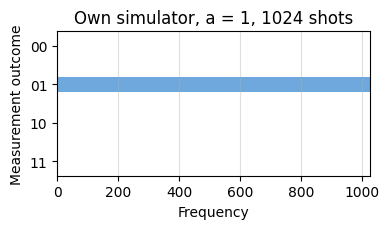

In [18]:
# --- Problem 14: measurement statistics, every target a, and a cross-check against Qiskit ---
rng = np.random.default_rng(SEED)
for a in range(4):
    sim = figure1(a)
    cnt = sim.measure(SHOTS, rng)
    qc = QuantumCircuit(2)
    qc.h([0, 1])
    for q in (0, 1):
        if not (a >> q) & 1:
            qc.x(q)
    qc.cz(1, 0)
    for q in (0, 1):
        if not (a >> q) & 1:
            qc.x(q)
    qc.h([0, 1]); qc.z([0, 1]); qc.cz(1, 0); qc.h([0, 1])
    same = np.allclose(Statevector(qc).data, sim.state)
    print(f"Problem 14  --  a = {a} (|{a:02b}>):  counts {cnt},  matches Qiskit Statevector ? {same}")

fig, ax = plt.subplots(figsize=(4, 2.4))
cnt = figure1(1).measure(SHOTS, rng)
keys = ["11", "10", "01", "00"]
ax.barh(keys, [cnt.get(k, 0) for k in keys], color="#6fa8dc", height=0.4)
ax.set_xlim(0, SHOTS); ax.set_xlabel("Frequency"); ax.set_ylabel("Measurement outcome")
ax.set_title(f"Own simulator, a = 1, {SHOTS} shots"); ax.grid(axis="x", alpha=0.4)
fig.tight_layout()
fig.savefig("../images/problem-14-answer.png", dpi=200, bbox_inches="tight")
display(fig)
plt.close(fig)

---

## **15. Implement Grover's Algorithm with XOR Gate**

In [19]:
# --- Problem 15: XOR oracle for a = 1 with n = 2 query qubits (q2 = MSB, q1) and m = 1 auxiliary (q0 = LSB) ---
f = lambda x: int(x == 1)
U_xor = xor_oracle(f, 2, 1)                       # |x>_2 |y>_1 -> |x>_2 |y XOR f(x)>_1
for i in range(8):
    j = int(np.argmax(U_xor[:, i]))
    if i != j:
        print(f"Problem 15  --  U_f |{i:03b}> = |{j:03b}>")
display(Math(r"U_f = " + latex_matrix(U_xor)))


def xor_oracle_gates():
    qc = QuantumCircuit(3, name="U_f")
    qc.x(2)                  # x = 01 has q2 = 0: flip it so the Toffoli fires on x = 01
    qc.ccx(2, 1, 0)          # y -> y XOR (q2' AND q1)
    qc.x(2)
    return qc


print("Problem 15  --  X, Toffoli, X matches the matrix ?", np.allclose(Operator(xor_oracle_gates()).data, U_xor))
minus = np.array([1, -1]) / np.sqrt(2)
V = np.diag([1, -1, 1, 1])
ok = all(np.allclose(U_xor @ np.kron(ket(format(x, "02b")), minus), np.kron(V @ ket(format(x, "02b")), minus)) for x in range(4))
print("Problem 15  --  U_f |x>|-> == (V|x>)|-> for every x ?", ok)

Problem 15  --  U_f |010> = |011>
Problem 15  --  U_f |011> = |010>


<IPython.core.display.Math object>

Problem 15  --  X, Toffoli, X matches the matrix ? True
Problem 15  --  U_f |x>|-> == (V|x>)|-> for every x ? True


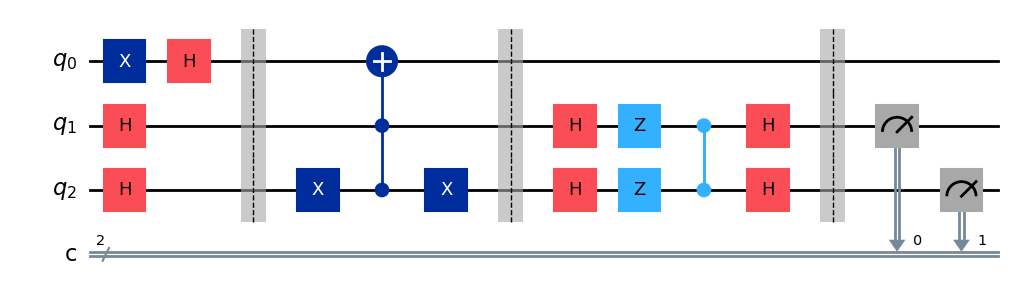

Problem 15  --  final state == |01>|-> ? True


1 iteration(s), ideal  (bit string q2 q1)
  00:     0 / 1024
  01:  1024 / 1024
  10:     0 / 1024
  11:     0 / 1024
1 iteration(s), noisy  (bit string q2 q1)
  00:    13 / 1024
  01:  1003 / 1024
  10:     5 / 1024
  11:     3 / 1024


2 iteration(s), ideal  (bit string q2 q1)
  00:   267 / 1024
  01:   257 / 1024
  10:   275 / 1024
  11:   225 / 1024
2 iteration(s), noisy  (bit string q2 q1)
  00:   267 / 1024
  01:   274 / 1024
  10:   243 / 1024
  11:   240 / 1024


1 iteration + auxiliary uncomputed, ideal  (q2 q1 q0)
  000:     0 / 1024
  001:     0 / 1024
  010:  1024 / 1024
  011:     0 / 1024
  100:     0 / 1024
  101:     0 / 1024
  110:     0 / 1024
  111:     0 / 1024
1 iteration + auxiliary uncomputed, noisy  (q2 q1 q0)
  000:    11 / 1024
  001:     4 / 1024
  010:   987 / 1024
  011:    10 / 1024
  100:     6 / 1024
  101:     1 / 1024
  110:     5 / 1024
  111:     0 / 1024


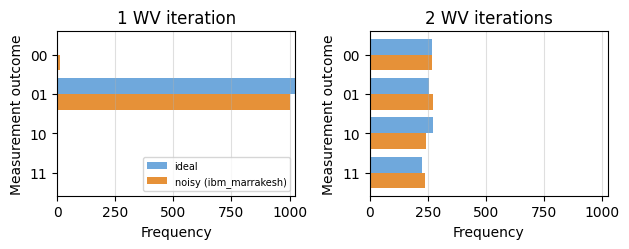

Problem 15  --  transpiled for ibm_marrakesh: depth 50  two-qubit gates 10


In [20]:
# --- Problem 15: the circuit of Figure 2 (one WV, since theta = 30 deg) ---
def figure2(iterations=1, uncompute=False):
    q, c = QuantumRegister(3, "q"), ClassicalRegister(3 if uncompute else 2, "c")
    qc = QuantumCircuit(q, c)
    qc.x(0); qc.h(0)                         # auxiliary |0> -> |->
    qc.h([1, 2])                             # |Phi>_2
    for _ in range(iterations):
        qc.barrier()
        qc.compose(xor_oracle_gates(), inplace=True)     # U_f = V
        qc.barrier()
        qc.h([1, 2]); qc.z([1, 2]); qc.cz(2, 1); qc.h([1, 2])   # W
    qc.barrier()
    if uncompute:
        qc.h(0); qc.x(0)                     # |-> -> |1> -> |0>
        qc.measure([0, 1, 2], [0, 1, 2])     # bit string q2 q1 q0
    else:
        qc.measure([1, 2], [0, 1])           # bit string q2 q1 = x
    return qc


display(figure2().draw("mpl", fold=-1))
plt.close("all")

body = figure2().remove_final_measurements(inplace=False)
sv = Statevector(body).data
print("Problem 15  --  final state == |01>|-> ?", np.allclose(sv, np.kron(ket("01"), minus)))

panels = []
for k in (1, 2):
    ci, cn = run(figure2(k), ideal), run(figure2(k), noisy)
    report(ci, f"{k} iteration(s), ideal  (bit string q2 q1)", 2)
    report(cn, f"{k} iteration(s), noisy  (bit string q2 q1)", 2)
    panels.append((f"{k} WV iteration" + ("s" if k > 1 else ""), ci, cn))
ci, cn = run(figure2(1, True), ideal), run(figure2(1, True), noisy)
report(ci, "1 iteration + auxiliary uncomputed, ideal  (q2 q1 q0)", 3)
report(cn, "1 iteration + auxiliary uncomputed, noisy  (q2 q1 q0)", 3)
histograms(panels, "problem-15-answer.png", 2)
tqc = transpile(figure2(), backend, optimization_level=1, seed_transpiler=SEED)
print("Problem 15  --  transpiled for ibm_marrakesh: depth", tqc.depth(), " two-qubit gates", tqc.count_ops().get("cz", 0))

---